In [1]:
import re
import pandas as pd

filename = "kam-nu-20-01-000.d"

rows = []
current_cosz = None

with open(filename) as f:
    for line in f:

        line = line.strip()

        # detectar bloque cosZ
        m = re.search(r'cosZ\s*=\s*([-\d\.]+)\s*--\s*([-\d\.]+)', line)
        if m:
            z1 = float(m.group(1))
            z2 = float(m.group(2))
            current_cosz = 0.5*(z1+z2)
            continue

        # leer filas numéricas
        parts = line.split()

        if len(parts) == 5:
            try:
                E = float(parts[0])
                numu = float(parts[1])   # ajustar columna si necesario

                if current_cosz is not None and current_cosz < 0:
                    rows.append([E,current_cosz,numu])

            except:
                pass

df = pd.DataFrame(rows, columns=["Enu","cosz","numu"])

# sumar bins angulares
flux = df.groupby("Enu")["numu"].sum().reset_index()

# limitar a 1000 GeV
flux = flux[flux["Enu"] <= 1000]

# ordenar
flux = flux.sort_values("Enu")

flux.to_csv("up_numuflux_clean.csv", index=False)

print(flux.head())
print("Archivo creado: up_numuflux_clean.csv")

       Enu     numu
0  0.10000  93886.8
1  0.11220  81724.0
2  0.12589  70881.1
3  0.14125  61026.6
4  0.15849  52035.3
Archivo creado: up_numuflux_clean.csv


In [2]:
flux

,Enu,numu
0,0.10000,93886.800000
1,0.11220,81724.000000
2,0.12589,70881.100000
3,0.14125,61026.600000
4,0.15849,52035.300000
...,...,...
76,630.96000,0.000012
77,707.95000,0.000008
78,794.33000,0.000006
79,891.25000,0.000004


In [ ]:
import uproot

file = uproot.open("RHC_Flux_NOvA_ND_2017.root")

# Listar objetos y sus clases ROOT
for name, classname in file.classnames().items():
    print(f"{name}: {classname}")


In [ ]:
# Acceder al objeto flux_numu (ciclo 1, como en el notebook original)
flux_numu = file["flux_numu;1"]
print("Clase:", flux_numu.classname)

# GetEntries() corresponde a un TTree; otros objetos (por ejemplo TH1)
# requieren métodos diferentes para contar sus entradas.
if flux_numu.classname.startswith("TTree") or "RNTuple" in flux_numu.classname:
    print("Entradas:", flux_numu.num_entries)
elif flux_numu.classname.startswith(("TH1", "TH2", "TH3")):
    print("Entradas del histograma:", flux_numu.member("fEntries"))
    print("Contenido de bins:", flux_numu.values())
else:
    print("Objeto disponible; inspecciona sus miembros con flux_numu.members")


In [5]:
import uproot

f = uproot.open("gntp.0.ghep.1000_converted.root")
print(f.keys())

['Event;1', 'Particles;1']


In [6]:
event = f["Event"]
particles = f["Particles"]

print(event.keys())
print(particles.keys())

['nupdg', 'nuE', 'nuPx', 'nuPy', 'nuPz', 'xsection', 'IsQE', 'IsRES', 'IsDIS', 'IsCoh', 'IsMEC', 'IsCC', 'IsNC']
['status', 'pdg', 'energy', 'px', 'py', 'pz']


In [7]:
import awkward as ak

pp = particles.arrays(library="ak")
pp

<Array [{status: [0, ...], pdg: ..., ...}, ...] type='1000 * {status: var *...'>

In [8]:
ev = event.arrays(library="pd")

In [9]:
ev[["nuE","nuPx","nuPy","nuPz"]].head(10)

,nuE,nuPx,nuPy,nuPz
0,0.389583,0.0,0.0,0.389583
1,0.771272,0.0,0.0,0.771272
2,0.529299,0.0,0.0,0.529299
3,9.331947,0.0,0.0,9.331947
4,1.798500,0.0,0.0,1.798500
5,0.950214,0.0,0.0,0.950214
6,0.731349,0.0,0.0,0.731349
7,0.141495,0.0,0.0,0.141495
8,1.024775,0.0,0.0,1.024775
9,3.444031,0.0,0.0,3.444031


In [10]:
ev["IsDIS"].mean()

0.179

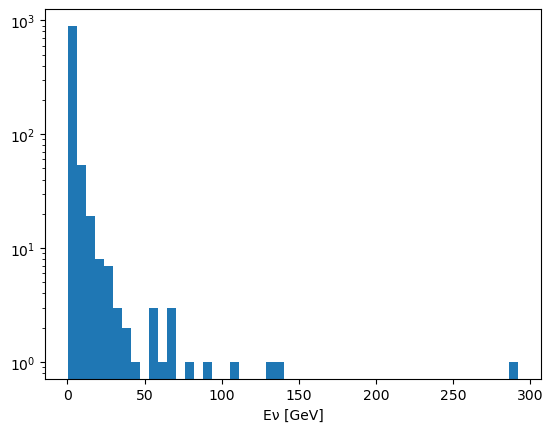

In [11]:
import matplotlib.pyplot as plt
plt.hist(ev["nuE"], bins=50, log=True)
plt.xlabel("Eν [GeV]")
plt.show()

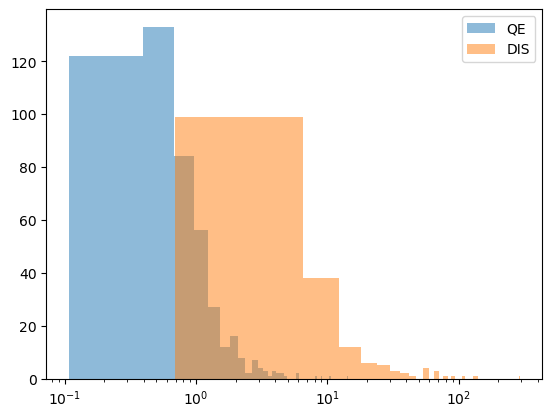

In [12]:
plt.hist(ev[ev["IsQE"]]["nuE"], bins=50, alpha=0.5, label="QE")
plt.hist(ev[ev["IsDIS"]]["nuE"], bins=50, alpha=0.5, label="DIS")
plt.xscale("log")
plt.legend()

In [13]:
(ev["nuPx"] != 0).sum(), (ev["nuPy"] != 0).sum()

(0, 0)

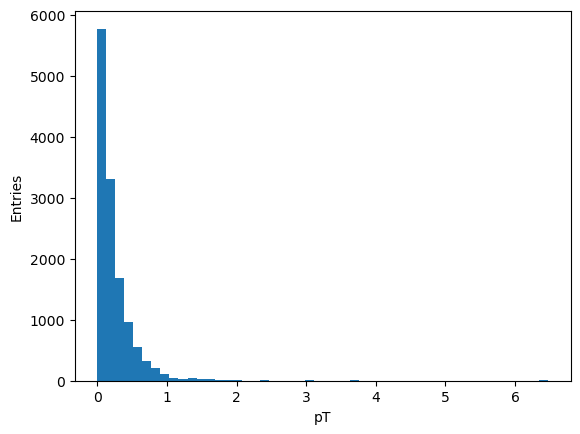

In [14]:
import numpy as np 
pt = np.sqrt(ak.to_numpy(ak.flatten(pp["px"]**2 + pp["py"]**2)))

import matplotlib.pyplot as plt
plt.hist(pt, bins=50)
plt.xlabel("pT")
plt.ylabel("Entries")
plt.show()

In [15]:
mask = (pp["status"] == 1)
px_final = pp["px"][mask]
py_final = pp["py"][mask]

In [16]:
ak.sum(px_final != 0), ak.sum(py_final != 0)

(5171, 5171)

In [17]:
import awkward as ak

# todas las partículas finales
final_mask = (pp["status"] == 1)

# muones finales
mu_minus = final_mask & (pp["pdg"] == 13)
mu_plus  = final_mask & (pp["pdg"] == -13)

n_mu_minus_total = ak.sum(mu_minus)
n_mu_plus_total  = ak.sum(mu_plus)

print("mu- finales:", n_mu_minus_total)
print("mu+ finales:", n_mu_plus_total)

mu- finales: 676
mu+ finales: 0


In [18]:
events_with_mu_minus = ak.sum(ak.any(mu_minus, axis=1))
events_with_mu_plus  = ak.sum(ak.any(mu_plus, axis=1))

print("Eventos con al menos un mu-:", events_with_mu_minus)
print("Eventos con al menos un mu+:", events_with_mu_plus)

Eventos con al menos un mu-: 676
Eventos con al menos un mu+: 0


In [19]:
pp = particles.arrays(library="ak")

In [20]:
import awkward as ak
import numpy as np
import matplotlib.pyplot as plt

mu_mask = (pp["status"] == 1) & (pp["pdg"] == 13) # status ==1 particuals finales

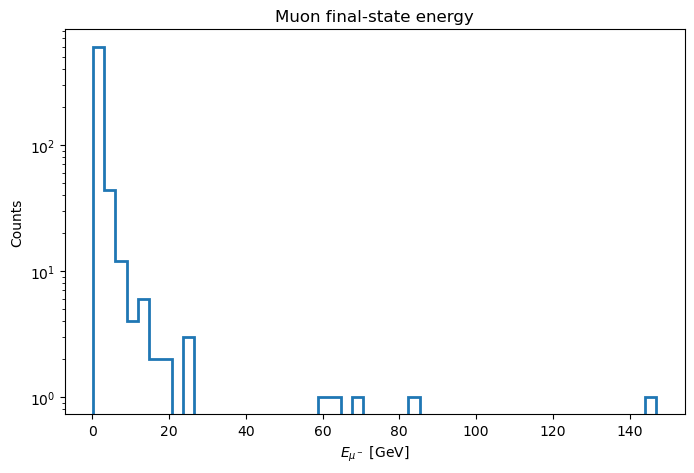

In [21]:
muE = ak.to_numpy(ak.flatten(pp["energy"][mu_mask]))

plt.figure(figsize=(8,5))
plt.hist(muE, bins=50, histtype="step", linewidth=2)
plt.xlabel(r"$E_{\mu^-}$ [GeV]")
plt.ylabel("Counts")
plt.title("Muon final-state energy")
plt.yscale("log")
plt.show()

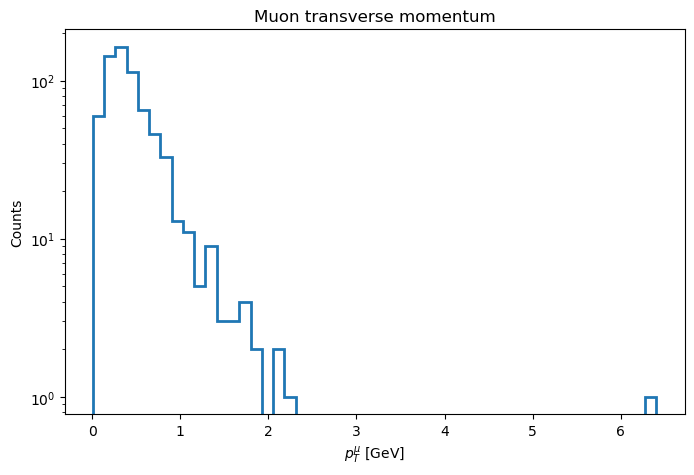

In [22]:
px = pp["px"][mu_mask]
py = pp["py"][mu_mask]

pt = ak.to_numpy(ak.flatten(np.sqrt(px**2 + py**2)))

plt.figure(figsize=(8,5))
plt.hist(pt, bins=50, histtype="step", linewidth=2)
plt.xlabel(r"$p_T^\mu$ [GeV]")
plt.ylabel("Counts")
plt.title("Muon transverse momentum")
plt.yscale("log")
plt.show()

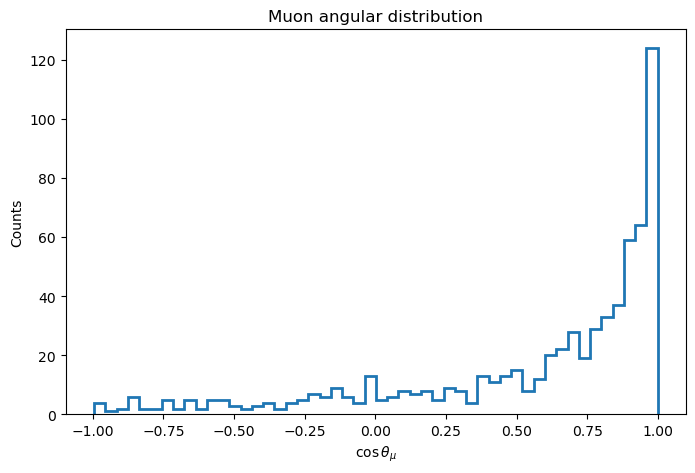

In [23]:
pz = pp["pz"][mu_mask]
p = np.sqrt(px**2 + py**2 + pz**2)

costh = ak.to_numpy(ak.flatten(pz/p))

plt.figure(figsize=(8,5))
plt.hist(costh, bins=50, histtype="step", linewidth=2)
plt.xlabel(r"$\cos\theta_\mu$")
plt.ylabel("Counts")
plt.title("Muon angular distribution")
plt.show()

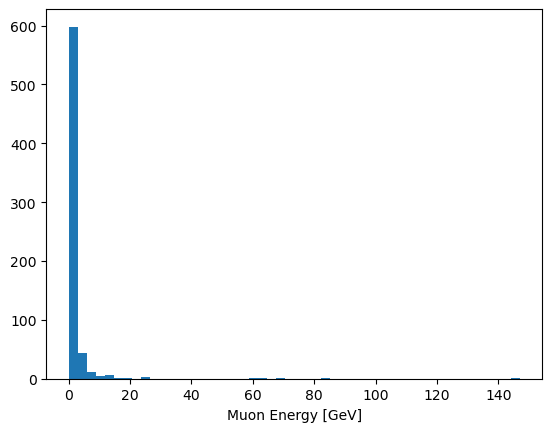

In [24]:
mu_mask = (pp["status"] == 1) & (pp["pdg"] == 13)
muE = ak.to_numpy(ak.flatten(pp["energy"][mu_mask]))

plt.hist(muE, bins=50)
plt.xlabel("Muon Energy [GeV]")
plt.show()

In [25]:
dis = ev[ev['IsDIS'] == True]
dis

,nupdg,nuE,nuPx,nuPy,nuPz,xsection,IsQE,IsRES,IsDIS,IsCoh,IsMEC,IsCC,IsNC
3,14,9.331947,0.0,0.0,9.331947,2.167466e-37,False,False,True,False,False,True,False
9,14,3.444031,0.0,0.0,3.444031,1.191823e-37,False,False,True,False,False,True,False
17,14,11.594014,0.0,0.0,11.594014,6.335624e-37,False,False,True,False,False,True,False
24,14,2.355049,0.0,0.0,2.355049,5.321812e-38,False,False,True,False,False,True,False
27,14,136.840272,0.0,0.0,136.840272,9.841224e-37,False,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
980,14,1.296482,0.0,0.0,1.296482,1.123162e-39,False,False,True,False,False,False,True
983,14,4.441483,0.0,0.0,4.441483,1.829185e-37,False,False,True,False,False,True,False
986,14,14.100402,0.0,0.0,14.100402,7.872411e-37,False,False,True,False,False,True,False
988,14,23.410322,0.0,0.0,23.410322,2.554521e-37,False,False,True,False,False,False,True


/tmp/ipykernel_42037/4084526370.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grp = dis2.groupby("bin").agg({


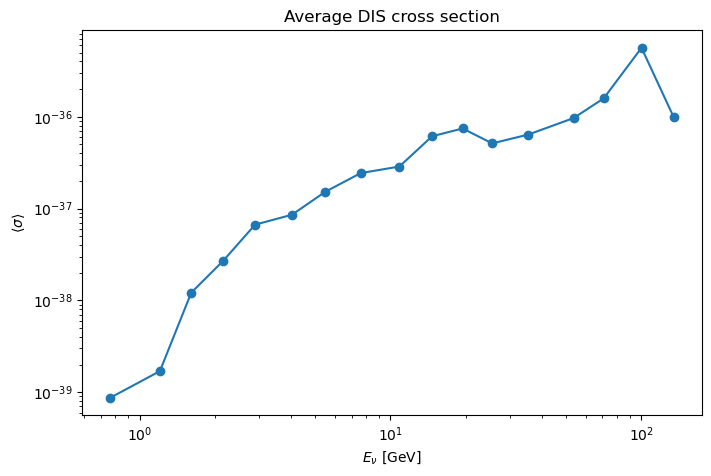

In [26]:
import numpy as np
import pandas as pd

bins = np.logspace(np.log10(dis['nuE'].min()), np.log10(dis['nuE'].max()), 20)

dis2 = dis.copy()
dis2["bin"] = pd.cut(dis2["nuE"], bins)

grp = dis2.groupby("bin").agg({
    "nuE":"mean",
    "xsection":"mean"
}).dropna()

plt.figure(figsize=(8,5))
plt.plot(grp["nuE"], grp["xsection"], marker="o")
plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$E_\nu$ [GeV]")
plt.ylabel(r"$\langle \sigma \rangle$")
plt.title("Average DIS cross section")
plt.show()

In [27]:
dis_numu_cc = ev[
    (ev["nupdg"] == 14) &
    (ev["IsDIS"] == True) &
    (ev["IsCC"] == True)
].copy()

In [28]:
len(dis_numu_cc)


133

In [29]:
dis_numu_cc[["nupdg", "nuE", "IsDIS", "IsCC", "IsNC"]].head()

,nupdg,nuE,IsDIS,IsCC,IsNC
3,14,9.331947,True,True,False
9,14,3.444031,True,True,False
17,14,11.594014,True,True,False
24,14,2.355049,True,True,False
27,14,136.840272,True,True,False


In [30]:
print(ev.columns)
print(pp.fields)

Index(['nupdg', 'nuE', 'nuPx', 'nuPy', 'nuPz', 'xsection', 'IsQE', 'IsRES',
       'IsDIS', 'IsCoh', 'IsMEC', 'IsCC', 'IsNC'],
      dtype='object')
['status', 'pdg', 'energy', 'px', 'py', 'pz']


In [31]:
dis_numu_cc

,nupdg,nuE,nuPx,nuPy,nuPz,xsection,IsQE,IsRES,IsDIS,IsCoh,IsMEC,IsCC,IsNC
3,14,9.331947,0.0,0.0,9.331947,2.167466e-37,False,False,True,False,False,True,False
9,14,3.444031,0.0,0.0,3.444031,1.191823e-37,False,False,True,False,False,True,False
17,14,11.594014,0.0,0.0,11.594014,6.335624e-37,False,False,True,False,False,True,False
24,14,2.355049,0.0,0.0,2.355049,5.321812e-38,False,False,True,False,False,True,False
27,14,136.840272,0.0,0.0,136.840272,9.841224e-37,False,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
947,14,17.007268,0.0,0.0,17.007268,9.634020e-37,False,False,True,False,False,True,False
975,14,3.920054,0.0,0.0,3.920054,6.538604e-38,False,False,True,False,False,True,False
983,14,4.441483,0.0,0.0,4.441483,1.829185e-37,False,False,True,False,False,True,False
986,14,14.100402,0.0,0.0,14.100402,7.872411e-37,False,False,True,False,False,True,False


/tmp/ipykernel_42037/2692306349.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grp = dis2.groupby("bin").agg({


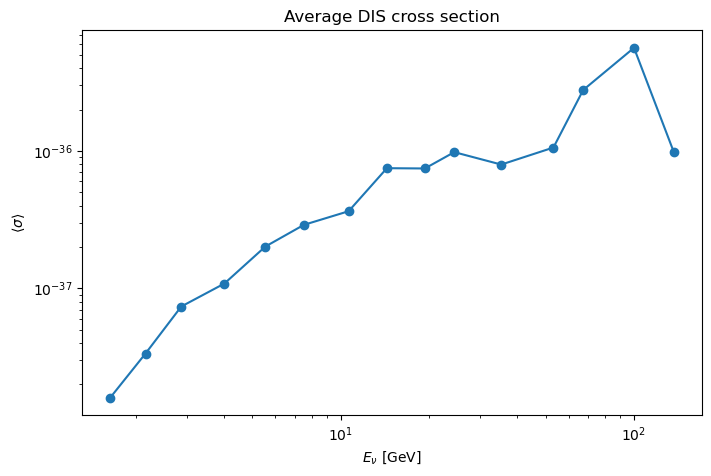

In [32]:
bins = np.logspace(np.log10(dis_numu_cc['nuE'].min()), np.log10(dis_numu_cc['nuE'].max()), 20)

dis2 = dis_numu_cc.copy()
dis2["bin"] = pd.cut(dis2["nuE"], bins)

grp = dis2.groupby("bin").agg({
    "nuE":"mean",
    "xsection":"mean"
}).dropna()

plt.figure(figsize=(8,5))
plt.plot(grp["nuE"], grp["xsection"], marker="o")
plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$E_\nu$ [GeV]")
plt.ylabel(r"$\langle \sigma \rangle$")
plt.title("Average DIS cross section")
plt.show()

In [33]:
ev["nupdg"].value_counts()

nupdg
14    1000
Name: count, dtype: int64

In [34]:
print(ev.columns)

Index(['nupdg', 'nuE', 'nuPx', 'nuPy', 'nuPz', 'xsection', 'IsQE', 'IsRES',
       'IsDIS', 'IsCoh', 'IsMEC', 'IsCC', 'IsNC'],
      dtype='object')


### A continuación abriré el output de GENIE para visualizar la información de los muones que salieron

In [35]:
pip install uproot awkward pandas numpy

Note: you may need to restart the kernel to use updated packages.


In [36]:
import uproot

file = uproot.open("gntp.0.ghep.1000_converted.root")

print(file.keys())

['Event;1', 'Particles;1']


In [37]:
particles = file['Particles']
event = file['Event']


In [38]:
print(particles.keys())

['status', 'pdg', 'energy', 'px', 'py', 'pz']


In [39]:
print(event.keys())

['nupdg', 'nuE', 'nuPx', 'nuPy', 'nuPz', 'xsection', 'IsQE', 'IsRES', 'IsDIS', 'IsCoh', 'IsMEC', 'IsCC', 'IsNC']


In [40]:
import awkward as ak

arr = particles.arrays(library="ak")

pdg = arr["pdg"]

mu_mask = (pdg == 13) | (pdg == -13)

muons = arr[mu_mask]


In [41]:
muons

<Array [{status: [1], pdg: [13], ...}, ...] type='1000 * {status: var * int...'>

In [42]:

import awkward as ak

E_mu = ak.flatten(muons.energy)

print(E_mu)

[0.251, 0.359, 4.62, 0.445, 0.188, 0.891, ..., 4.06, 0.725, 0.522, 0.257, 18.3]


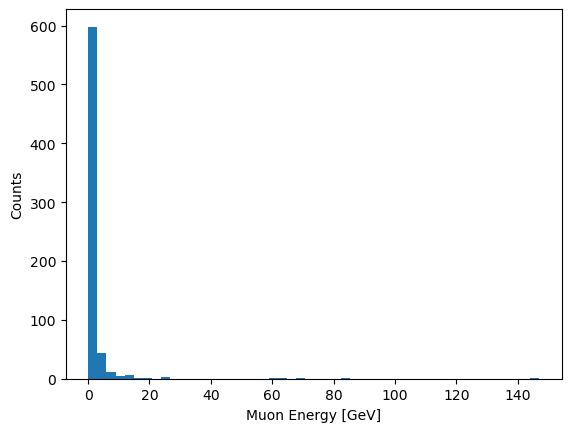

In [43]:
import matplotlib.pyplot as plt

plt.hist(E_mu, bins=50)
plt.xlabel("Muon Energy [GeV]")
plt.ylabel("Counts")
plt.show()

In [44]:
has_muon = ak.num(muons.energy) > 0

events_with_muon = arr[has_muon]

In [45]:
events_with_muon

<Array [{status: [0, ...], pdg: ..., ...}, ...] type='676 * {status: var * ...'>

In [51]:
import awkward as ak
import pandas as pd
import numpy as np

# muons ya viene de:
# muons = arr[mu_mask]

# -----------------------------------
# Flatten de todas las ramas
# -----------------------------------
pdg    = ak.to_numpy(ak.flatten(muons.pdg))
status = ak.to_numpy(ak.flatten(muons.status))
E      = ak.to_numpy(ak.flatten(muons.energy))
px     = ak.to_numpy(ak.flatten(muons.px))
py     = ak.to_numpy(ak.flatten(muons.py))
pz     = ak.to_numpy(ak.flatten(muons.pz))

# -----------------------------------
# Momento total
# -----------------------------------
p = np.sqrt(px**2 + py**2 + pz**2)

# cos(theta)
costheta = pz / p

# theta en grados
theta = np.degrees(np.arccos(costheta))

# -----------------------------------
# Crear DataFrame
# -----------------------------------
df_muons = pd.DataFrame({
    "pdg": pdg,
    "status": status,
    "energy_GeV": E,
    "px_GeV": px,
    "py_GeV": py,
    "pz_GeV": pz,
    "p_GeV": p,
    "costheta": costheta,
    "theta_deg": theta
})

print(df_muons.head(20))


# -----------------------------------
# Guardar dataset en CSV
# -----------------------------------
output_file = "muons_dataset.csv"

df_muons.to_csv(output_file, index=False)

print(f"Dataset guardado en: {output_file}")
print(f"Número de muones guardados: {len(df_muons)}")

    pdg  status  energy_GeV    px_GeV    py_GeV    pz_GeV     p_GeV  costheta  \
0    13       1    0.251116  0.198117  0.089615  0.067926  0.227806  0.298175   
1    13       1    0.358665  0.205295  0.219055  0.165366  0.342749  0.482469   
2    13       1    4.620015 -0.689894  0.116667  4.565502  4.618806  0.988459   
3    13       1    0.445293 -0.326458 -0.120750  0.256840  0.432576  0.593745   
4    13       1    0.187770 -0.147066  0.038763  0.031031  0.155222  0.199915   
5    13       1    0.891224  0.362267  0.095516  0.801720  0.884939  0.905962   
6    13       1    2.080036  0.374027  0.357148  2.011948  2.077351  0.968516   
7    13       1    1.071440 -0.042673 -0.094496  1.061164  1.066217  0.995260   
8    13       1    0.628849  0.135620  0.466230  0.385387  0.619909  0.621684   
9    13       1    0.978577 -0.365990 -0.246814  0.866939  0.972856  0.891128   
10   13       1    0.496317  0.469878  0.119405 -0.011115  0.484940 -0.022919   
11   13       1    1.265866 

In [52]:
df_muons

,pdg,status,energy_GeV,px_GeV,py_GeV,pz_GeV,p_GeV,costheta,theta_deg
0,13,1,0.251116,0.198117,0.089615,0.067926,0.227806,0.298175,72.651976
1,13,1,0.358665,0.205295,0.219055,0.165366,0.342749,0.482469,61.153203
2,13,1,4.620015,-0.689894,0.116667,4.565502,4.618806,0.988459,8.713113
3,13,1,0.445293,-0.326458,-0.120750,0.256840,0.432576,0.593745,53.576792
4,13,1,0.187770,-0.147066,0.038763,0.031031,0.155222,0.199915,78.468033
...,...,...,...,...,...,...,...,...,...
671,13,1,4.060988,0.206505,-0.308614,4.042594,4.059613,0.995808,5.248159
672,13,1,0.725134,0.069340,0.447151,0.556689,0.717395,0.775987,39.105387
673,13,1,0.522459,0.228140,0.064661,0.453399,0.511663,0.886127,27.609471
674,13,1,0.257195,-0.038095,0.231373,-0.000879,0.234490,-0.003750,90.214884


#### Hasta ahora tengo el dataset de los muones, sin embargo necesitamos hacer un merge con el árbol 'events' para agregarle la información de isDIS y isCC.

In [53]:
print(particles.keys())

['status', 'pdg', 'energy', 'px', 'py', 'pz']


In [54]:
print(event.keys())

['nupdg', 'nuE', 'nuPx', 'nuPy', 'nuPz', 'xsection', 'IsQE', 'IsRES', 'IsDIS', 'IsCoh', 'IsMEC', 'IsCC', 'IsNC']


In [55]:
evt = event.arrays(library="ak")

# muones flattened
df_mu = pd.DataFrame({
    "event": np.repeat(np.arange(len(muons)), ak.num(muons.pdg)),
    "pdg": ak.to_numpy(ak.flatten(muons.pdg)),
    "E": ak.to_numpy(ak.flatten(muons.energy))
})

# tabla de eventos
df_evt = pd.DataFrame({
    "event": np.arange(len(evt)),
    "isCC": ak.to_numpy(evt.IsCC),
    "isNC": ak.to_numpy(evt.IsNC),
    "isQE": ak.to_numpy(evt.IsQE),
    "isDIS": ak.to_numpy(evt.IsDIS),
    "isRES": ak.to_numpy(evt.IsRES)
})

# unir
df = df_mu.merge(df_evt, on="event")

In [56]:
df

,event,pdg,E,isCC,isNC,isQE,isDIS,isRES
0,0,13,0.251116,True,False,True,False,False
1,1,13,0.358665,True,False,False,False,False
2,3,13,4.620015,True,False,False,True,False
3,5,13,0.445293,True,False,False,False,True
4,6,13,0.187770,True,False,False,False,True
...,...,...,...,...,...,...,...,...
671,989,13,4.060988,True,False,False,False,True
672,990,13,0.725134,True,False,True,False,False
673,991,13,0.522459,True,False,False,False,False
674,992,13,0.257195,True,False,True,False,False


In [57]:
import awkward as ak
import pandas as pd
import numpy as np

# =====================================================
# 1. Leer árbol Event
# =====================================================
evt = event.arrays(library="ak")

# =====================================================
# 2. Número de muones por evento
# =====================================================
nmu = ak.num(muons.pdg)

# =====================================================
# 3. Variables de muones (flatten)
# =====================================================
pdg    = ak.to_numpy(ak.flatten(muons.pdg))
status = ak.to_numpy(ak.flatten(muons.status))
E      = ak.to_numpy(ak.flatten(muons.energy))
px     = ak.to_numpy(ak.flatten(muons.px))
py     = ak.to_numpy(ak.flatten(muons.py))
pz     = ak.to_numpy(ak.flatten(muons.pz))

# =====================================================
# 4. Índice de evento repetido para cada muón
# =====================================================
event_id = np.repeat(np.arange(len(muons)), ak.to_numpy(nmu))

# =====================================================
# 5. Cinemática extra
# =====================================================
p = np.sqrt(px**2 + py**2 + pz**2) # Momentum total
costheta = pz / p
theta = np.degrees(np.arccos(costheta)) # angulo zenital?

# =====================================================
# 6. Crear tabla base de muones
# =====================================================
df_muons = pd.DataFrame({
    "event": event_id,
    "pdg": pdg,
    "status": status,
    "energy_GeV": E,
    "px_GeV": px,
    "py_GeV": py,
    "pz_GeV": pz,
    "p_GeV": p,
    "costheta": costheta,
    "theta_deg": theta
})

# =====================================================
# 7. Agregar flags del evento
# =====================================================
df_muons["IsCC"]  = ak.to_numpy(evt["IsCC"])[event_id]
df_muons["IsNC"]  = ak.to_numpy(evt["IsNC"])[event_id]
df_muons["IsQE"]  = ak.to_numpy(evt["IsQE"])[event_id]
df_muons["IsDIS"] = ak.to_numpy(evt["IsDIS"])[event_id]
df_muons["IsRES"] = ak.to_numpy(evt["IsRES"])[event_id]
df_muons["IsMEC"] = ak.to_numpy(evt["IsMEC"])[event_id]

# =====================================================
# 8. Mostrar resultado
# =====================================================
print(df_muons.head(20))

    event  pdg  status  energy_GeV    px_GeV    py_GeV    pz_GeV     p_GeV  \
0       0   13       1    0.251116  0.198117  0.089615  0.067926  0.227806   
1       1   13       1    0.358665  0.205295  0.219055  0.165366  0.342749   
2       3   13       1    4.620015 -0.689894  0.116667  4.565502  4.618806   
3       5   13       1    0.445293 -0.326458 -0.120750  0.256840  0.432576   
4       6   13       1    0.187770 -0.147066  0.038763  0.031031  0.155222   
5       8   13       1    0.891224  0.362267  0.095516  0.801720  0.884939   
6       9   13       1    2.080036  0.374027  0.357148  2.011948  2.077351   
7      10   13       1    1.071440 -0.042673 -0.094496  1.061164  1.066217   
8      11   13       1    0.628849  0.135620  0.466230  0.385387  0.619909   
9      12   13       1    0.978577 -0.365990 -0.246814  0.866939  0.972856   
10     13   13       1    0.496317  0.469878  0.119405 -0.011115  0.484940   
11     14   13       1    1.265866 -0.771442 -0.194490  0.978930

In [59]:
df_muons_dis = df_muons[
    (df_muons['IsDIS'] == True) &
    (df_muons['IsCC']  == True)
].copy()

In [60]:
df_muons_dis

,event,pdg,status,energy_GeV,px_GeV,py_GeV,pz_GeV,p_GeV,costheta,theta_deg,IsCC,IsNC,IsQE,IsDIS,IsRES,IsMEC
2,3,13,1,4.620015,-0.689894,0.116667,4.565502,4.618806,0.988459,8.713113,True,False,False,True,False,False
6,9,13,1,2.080036,0.374027,0.357148,2.011948,2.077351,0.968516,14.415386,True,False,False,True,False,False
14,17,13,1,1.293678,-0.480425,-0.364588,1.139609,1.289356,0.883858,27.888636,True,False,False,True,False,False
17,24,13,1,0.675858,0.168600,-0.368050,0.530786,0.667548,0.795128,37.332699,True,False,False,True,False,False
20,27,13,1,63.909684,-2.239751,0.200878,63.870022,63.909596,0.999381,2.016442,True,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
642,947,13,1,2.851641,0.490161,1.205627,2.535133,2.849683,0.889619,27.174551,True,False,False,True,False,False
659,975,13,1,1.125595,0.419056,-0.358636,0.975486,1.120625,0.870484,29.485086,True,False,False,True,False,False
666,983,13,1,2.667631,0.238132,0.614977,2.582671,2.665538,0.968912,14.324115,True,False,False,True,False,False
669,986,13,1,12.712840,0.459762,0.495544,12.694416,12.712401,0.998585,3.048116,True,False,False,True,False,False


#### Archivo con n = 10.000

In [61]:
import uproot
import awkward as ak


file = uproot.open("gntp.fluxnumu_O16-104_converted.root")

print(file.keys())

['Event;1', 'Particles;1']


In [62]:
particles = file['Particles']
event = file['Event']

print(particles.keys(),event.keys())

['status', 'pdg', 'energy', 'px', 'py', 'pz'] ['nupdg', 'nuE', 'nuPx', 'nuPy', 'nuPz', 'xsection', 'IsQE', 'IsRES', 'IsDIS', 'IsCoh', 'IsMEC', 'IsCC', 'IsNC', 'Q2', 'W']


In [63]:
arr = particles.arrays(library="ak")

pdg = arr["pdg"]

mu_mask = (pdg == 13) | (pdg == -13)

muons = arr[mu_mask]


In [64]:
muons

<Array [{status: [1], pdg: [13], ...}, ...] type='10000 * {status: var * in...'>

In [65]:
import awkward as ak
import pandas as pd
import numpy as np

# muons ya viene de:
# muons = arr[mu_mask]

# -----------------------------------
# Flatten de todas las ramas
# -----------------------------------
pdg    = ak.to_numpy(ak.flatten(muons.pdg))
status = ak.to_numpy(ak.flatten(muons.status))
E      = ak.to_numpy(ak.flatten(muons.energy))
px     = ak.to_numpy(ak.flatten(muons.px))
py     = ak.to_numpy(ak.flatten(muons.py))
pz     = ak.to_numpy(ak.flatten(muons.pz))

# -----------------------------------
# Momento total
# -----------------------------------
p = np.sqrt(px**2 + py**2 + pz**2)

# cos(theta)
costheta = pz / p

# theta en grados
theta = np.degrees(np.arccos(costheta))

# -----------------------------------
# Crear DataFrame
# -----------------------------------
df_muons = pd.DataFrame({
    "pdg": pdg,
    "status": status,
    "energy_GeV": E,
    "px_GeV": px,
    "py_GeV": py,
    "pz_GeV": pz,
    "p_GeV": p,
    "costheta": costheta,
    "theta_deg": theta
})

print(df_muons.head(20))

    pdg  status  energy_GeV    px_GeV    py_GeV    pz_GeV     p_GeV  costheta  \
0    13       1    0.251116  0.198117  0.089615  0.067926  0.227806  0.298175   
1    13       1    0.358665  0.205295  0.219055  0.165366  0.342749  0.482469   
2    13       1    4.620015 -0.689894  0.116667  4.565502  4.618806  0.988459   
3    13       1    0.445293 -0.326458 -0.120750  0.256840  0.432576  0.593745   
4    13       1    0.187770 -0.147066  0.038763  0.031031  0.155222  0.199915   
5    13       1    0.891224  0.362267  0.095516  0.801720  0.884939  0.905962   
6    13       1    2.080036  0.374027  0.357148  2.011948  2.077351  0.968516   
7    13       1    1.071440 -0.042673 -0.094496  1.061164  1.066217  0.995260   
8    13       1    0.628849  0.135620  0.466230  0.385387  0.619909  0.621684   
9    13       1    0.978577 -0.365990 -0.246814  0.866939  0.972856  0.891128   
10   13       1    0.496317  0.469878  0.119405 -0.011115  0.484940 -0.022919   
11   13       1    1.265866 

In [66]:
import awkward as ak
import pandas as pd
import numpy as np

# =====================================================
# 1. Leer árbol Event
# =====================================================
evt = event.arrays(library="ak")

# =====================================================
# 2. Número de muones por evento
# =====================================================
nmu = ak.num(muons.pdg)

# =====================================================
# 3. Variables de muones (flatten)
# =====================================================
pdg    = ak.to_numpy(ak.flatten(muons.pdg))
status = ak.to_numpy(ak.flatten(muons.status))
E      = ak.to_numpy(ak.flatten(muons.energy))
px     = ak.to_numpy(ak.flatten(muons.px))
py     = ak.to_numpy(ak.flatten(muons.py))
pz     = ak.to_numpy(ak.flatten(muons.pz))

# =====================================================
# 4. Índice de evento repetido para cada muón
# =====================================================
event_id = np.repeat(np.arange(len(muons)), ak.to_numpy(nmu))

# =====================================================
# 5. Cinemática extra
# =====================================================
p = np.sqrt(px**2 + py**2 + pz**2) # Momentum total
costheta = pz / p
theta = np.degrees(np.arccos(costheta)) # angulo zenital?

# =====================================================
# 6. Crear tabla base de muones
# =====================================================
df_muons = pd.DataFrame({
    "event": event_id,
    "pdg": pdg,
    "status": status,
    "energy_GeV": E,
    "px_GeV": px,
    "py_GeV": py,
    "pz_GeV": pz,
    "p_GeV": p,
    "costheta": costheta,
    "theta_deg": theta
})

# =====================================================
# 7. Agregar flags del evento
# =====================================================
df_muons["IsCC"]  = ak.to_numpy(evt["IsCC"])[event_id]
df_muons["IsNC"]  = ak.to_numpy(evt["IsNC"])[event_id]
df_muons["IsQE"]  = ak.to_numpy(evt["IsQE"])[event_id]
df_muons["IsDIS"] = ak.to_numpy(evt["IsDIS"])[event_id]
df_muons["IsRES"] = ak.to_numpy(evt["IsRES"])[event_id]
df_muons["IsMEC"] = ak.to_numpy(evt["IsMEC"])[event_id]

# =====================================================
# 8. Mostrar resultado
# =====================================================
print(df_muons.head(20))

    event  pdg  status  energy_GeV    px_GeV    py_GeV    pz_GeV     p_GeV  \
0       0   13       1    0.251116  0.198117  0.089615  0.067926  0.227806   
1       1   13       1    0.358665  0.205295  0.219055  0.165366  0.342749   
2       3   13       1    4.620015 -0.689894  0.116667  4.565502  4.618806   
3       5   13       1    0.445293 -0.326458 -0.120750  0.256840  0.432576   
4       6   13       1    0.187770 -0.147066  0.038763  0.031031  0.155222   
5       8   13       1    0.891224  0.362267  0.095516  0.801720  0.884939   
6       9   13       1    2.080036  0.374027  0.357148  2.011948  2.077351   
7      10   13       1    1.071440 -0.042673 -0.094496  1.061164  1.066217   
8      11   13       1    0.628849  0.135620  0.466230  0.385387  0.619909   
9      12   13       1    0.978577 -0.365990 -0.246814  0.866939  0.972856   
10     13   13       1    0.496317  0.469878  0.119405 -0.011115  0.484940   
11     14   13       1    1.265866 -0.771442 -0.194490  0.978930

In [67]:
df_muons

,event,pdg,status,energy_GeV,px_GeV,py_GeV,pz_GeV,p_GeV,costheta,theta_deg,IsCC,IsNC,IsQE,IsDIS,IsRES,IsMEC
0,0,13,1,0.251116,0.198117,0.089615,0.067926,0.227806,0.298175,72.651976,True,False,True,False,False,False
1,1,13,1,0.358665,0.205295,0.219055,0.165366,0.342749,0.482469,61.153203,True,False,False,False,False,True
2,3,13,1,4.620015,-0.689894,0.116667,4.565502,4.618806,0.988459,8.713113,True,False,False,True,False,False
3,5,13,1,0.445293,-0.326458,-0.120750,0.256840,0.432576,0.593745,53.576792,True,False,False,False,True,False
4,6,13,1,0.187770,-0.147066,0.038763,0.031031,0.155222,0.199915,78.468033,True,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6787,9994,13,1,0.254805,0.107306,0.096932,-0.181250,0.231866,-0.781700,141.416521,True,False,True,False,False,False
6788,9995,13,1,0.413216,0.340891,0.101754,0.181723,0.399480,0.454900,62.941478,True,False,False,False,True,False
6789,9997,13,1,2.007580,1.062198,0.724986,1.537967,2.004797,0.767143,39.901943,True,False,False,True,False,False
6790,9998,13,1,0.497703,0.395393,0.197690,0.202800,0.486358,0.416976,65.356152,True,False,False,False,False,True


In [68]:
df_muons_dis = df_muons[
    (df_muons['IsDIS'] == True) &
    (df_muons['IsCC']  == True)
].copy()

In [69]:
df_muons_dis

,event,pdg,status,energy_GeV,px_GeV,py_GeV,pz_GeV,p_GeV,costheta,theta_deg,IsCC,IsNC,IsQE,IsDIS,IsRES,IsMEC
2,3,13,1,4.620015,-0.689894,0.116667,4.565502,4.618806,0.988459,8.713113,True,False,False,True,False,False
6,9,13,1,2.080036,0.374027,0.357148,2.011948,2.077351,0.968516,14.415386,True,False,False,True,False,False
14,17,13,1,1.293678,-0.480425,-0.364588,1.139609,1.289356,0.883858,27.888636,True,False,False,True,False,False
17,24,13,1,0.675858,0.168600,-0.368050,0.530786,0.667548,0.795128,37.332699,True,False,False,True,False,False
20,27,13,1,63.909684,-2.239751,0.200878,63.870022,63.909596,0.999381,2.016442,True,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6776,9975,13,1,6.215729,1.725556,0.419448,5.955724,6.214831,0.958308,16.602874,True,False,False,True,False,False
6777,9977,13,1,4.715329,0.786058,1.128984,4.508954,4.714145,0.956473,16.966906,True,False,False,True,False,False
6779,9982,13,1,0.390019,0.321495,0.108101,0.160956,0.375435,0.428718,64.613789,True,False,False,True,False,False
6780,9983,13,1,0.261260,0.078860,-0.213861,0.071676,0.238941,0.299974,72.543965,True,False,False,True,False,False


In [70]:

# Guardar CSV
df_muons_dis.to_csv("muon_data.csv", index=False)

print(df_muons_dis.head())
print(f"\nArchivo guardado: puntos_volcan_lascar.csv")
print(f"Total puntos: {len(df)}")

    event  pdg  status  energy_GeV    px_GeV    py_GeV     pz_GeV      p_GeV  \
2       3   13       1    4.620015 -0.689894  0.116667   4.565502   4.618806   
6       9   13       1    2.080036  0.374027  0.357148   2.011948   2.077351   
14     17   13       1    1.293678 -0.480425 -0.364588   1.139609   1.289356   
17     24   13       1    0.675858  0.168600 -0.368050   0.530786   0.667548   
20     27   13       1   63.909684 -2.239751  0.200878  63.870022  63.909596   

    costheta  theta_deg  IsCC   IsNC   IsQE  IsDIS  IsRES  IsMEC  
2   0.988459   8.713113  True  False  False   True  False  False  
6   0.968516  14.415386  True  False  False   True  False  False  
14  0.883858  27.888636  True  False  False   True  False  False  
17  0.795128  37.332699  True  False  False   True  False  False  
20  0.999381   2.016442  True  False  False   True  False  False  

Archivo guardado: puntos_volcan_lascar.csv
Total puntos: 676


In [71]:
df_muons_dis

,event,pdg,status,energy_GeV,px_GeV,py_GeV,pz_GeV,p_GeV,costheta,theta_deg,IsCC,IsNC,IsQE,IsDIS,IsRES,IsMEC
2,3,13,1,4.620015,-0.689894,0.116667,4.565502,4.618806,0.988459,8.713113,True,False,False,True,False,False
6,9,13,1,2.080036,0.374027,0.357148,2.011948,2.077351,0.968516,14.415386,True,False,False,True,False,False
14,17,13,1,1.293678,-0.480425,-0.364588,1.139609,1.289356,0.883858,27.888636,True,False,False,True,False,False
17,24,13,1,0.675858,0.168600,-0.368050,0.530786,0.667548,0.795128,37.332699,True,False,False,True,False,False
20,27,13,1,63.909684,-2.239751,0.200878,63.870022,63.909596,0.999381,2.016442,True,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6776,9975,13,1,6.215729,1.725556,0.419448,5.955724,6.214831,0.958308,16.602874,True,False,False,True,False,False
6777,9977,13,1,4.715329,0.786058,1.128984,4.508954,4.714145,0.956473,16.966906,True,False,False,True,False,False
6779,9982,13,1,0.390019,0.321495,0.108101,0.160956,0.375435,0.428718,64.613789,True,False,False,True,False,False
6780,9983,13,1,0.261260,0.078860,-0.213861,0.071676,0.238941,0.299974,72.543965,True,False,False,True,False,False


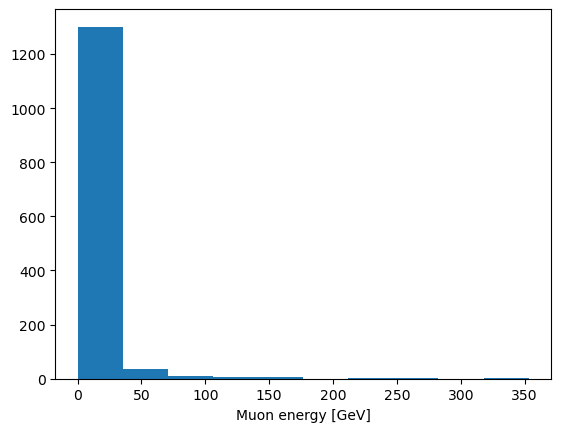

In [24]:
import matplotlib.pyplot as plt 

plt.hist(df_muons_dis['energy_GeV'])
plt.xlabel("Muon energy [GeV]")
plt.show()

## Muon angular distribution

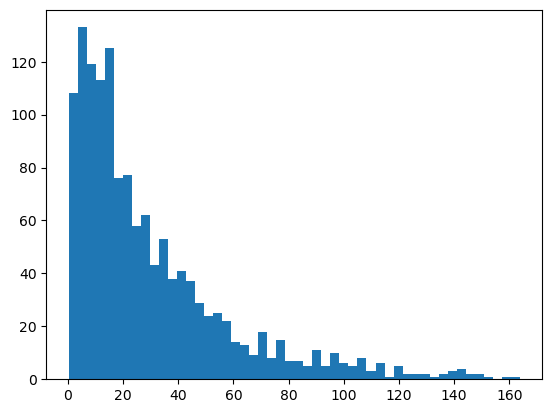

In [33]:
plt.hist(df_muons_dis["theta_deg"], bins=50)
plt.show()

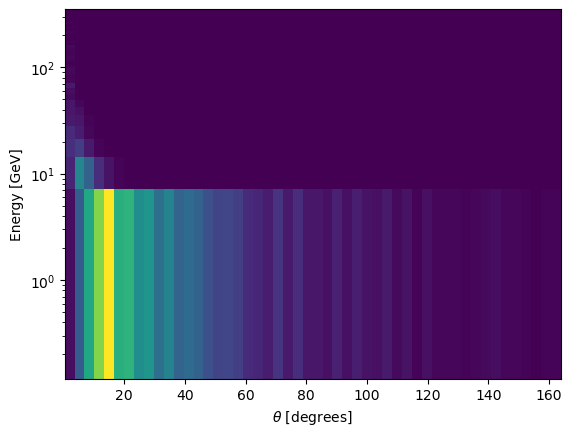

In [32]:
plt.hist2d(df_muons_dis["theta_deg"], df_muons_dis["energy_GeV"], bins=50)
plt.yscale("log")
plt.ylabel('Energy [GeV]')
plt.xlabel(r'$\theta$ [degrees]')
plt.show()

In [34]:
import numpy as np
import pandas as pd

# ============================================================
# GENERADOR DE PUNTOS EN UN CONO TRUNCADO (Volcán Lascar aprox.)
# ============================================================
# Sistema de coordenadas:
# z = altura vertical
# eje del cono en z
# centro en (0,0)
#
# x,y en metros
# z en metros
#
# ------------------------------------------------------------
# PARÁMETROS GEOMÉTRICOS (AJUSTABLES)
# Valores aproximados para Lascar
# ------------------------------------------------------------

H = 1800          # altura del cono truncado [m]
R_base = 3000     # radio en la base [m]
R_top = 400       # radio en la cima truncada [m]

# Cantidad total de puntos deseados
N = 50000

# ------------------------------------------------------------
# CONTROL DE DENSIDAD VERTICAL
# alpha = 1   -> uniforme en volumen
# alpha > 1   -> más puntos abajo
# alpha < 1   -> más puntos arriba
# Recomiendo alpha=2 o 3
# ------------------------------------------------------------

alpha = 2.5

# ============================================================
# FUNCIÓN RADIO(z)
# ============================================================

def radius(z):
    """
    Radio del cono truncado a altura z
    z=0 base
    z=H cima
    """
    return R_base + (R_top - R_base) * (z / H)

# ============================================================
# MUESTREO EN z
# ============================================================
# Variable u uniforme [0,1]
# Transformación para concentrar puntos abajo:
# z = H * u^(alpha)

u = np.random.rand(N)
z = H * (u ** alpha)

# ============================================================
# MUESTREO UNIFORME EN CADA DISCO TRANSVERSAL
# ============================================================

rmax = radius(z)

theta = 2 * np.pi * np.random.rand(N)

# sqrt para distribución uniforme en área
r = rmax * np.sqrt(np.random.rand(N))

x = r * np.cos(theta)
y = r * np.sin(theta)

# ============================================================
# TABLA FINAL
# ============================================================

df = pd.DataFrame({
    "x_m": x,
    "y_m": y,
    "z_m": z
})

# Guardar CSV
df.to_csv("puntos_volcan_lascar.csv", index=False)

print(df.head())
print(f"\nArchivo guardado: puntos_volcan_lascar.csv")
print(f"Total puntos: {len(df)}")

           x_m          y_m          z_m
0    -7.121365   -23.394535  1799.268832
1  1210.861278 -1083.187397   808.332441
2   416.261473  2344.214244   118.513894
3  -234.124898  1589.438260   821.603199
4  -277.549232  -410.863889  1600.954169

Archivo guardado: puntos_volcan_lascar.csv
Total puntos: 50000


In [37]:
import numpy as np
import pandas as pd

# ==========================================================
# LEER TUS MUONES
# ==========================================================
df = pd.read_csv("muon_data.csv")

# ==========================================================
# GEOMETRÍA VOLCÁN LÁSCAR (ajustable)
# ==========================================================
H = 1800.0       # altura [m]
R_base = 3000.0  # radio base [m]
R_top = 400.0    # radio cima [m]

# ==========================================================
# FUNCIÓN RADIO(z)
# ==========================================================
def radius(z):
    return R_base + (R_top - R_base) * (z / H)

# ==========================================================
# VERIFICAR SI UN PUNTO ESTÁ DENTRO DEL CONO
# ==========================================================
def inside_volcano(x, y, z):

    if z < 0 or z > H:
        return False

    r = np.sqrt(x**2 + y**2)
    return r <= radius(z)

# ==========================================================
# NORMALIZAR DIRECCIONES DE MUONES
# ==========================================================
p = np.sqrt(df["px_GeV"]**2 + df["py_GeV"]**2 + df["pz_GeV"]**2)

df["ux"] = df["px_GeV"] / p
df["uy"] = df["py_GeV"] / p
df["uz"] = df["pz_GeV"] / p

# ==========================================================
# GENERAR PUNTOS DENTRO DEL VOLCÁN USANDO TRAYECTORIAS
# ==========================================================
points = []

N_steps = 200        # pasos por muón
step_size = 20.0     # metros

for _, row in df.iterrows():

    ux, uy, uz = row["ux"], row["uy"], row["uz"]

    # Solo muones descendentes
    if uz >= 0:
        continue

    # Punto inicial aleatorio en tapa superior
    theta = np.random.uniform(0, 2*np.pi)
    r = R_top * np.sqrt(np.random.rand())

    x0 = r*np.cos(theta)
    y0 = r*np.sin(theta)
    z0 = H

    for i in range(N_steps):

        s = i * step_size

        x = x0 + ux*s
        y = y0 + uy*s
        z = z0 + uz*s

        if inside_volcano(x, y, z):
            points.append([x, y, z, row["energy_GeV"]])
        else:
            break

# ==========================================================
# GUARDAR RESULTADO
# ==========================================================
out = pd.DataFrame(points, columns=["x_m", "y_m", "z_m", "energy_GeV"])

out.to_csv("puntos_muones_lascar.csv", index=False)

print(out.head())
print("Total puntos:", len(out))

          x_m        y_m          z_m  energy_GeV
0 -279.276872  179.44763  1800.000000    0.207408
1 -264.201474  187.78277  1789.838415    0.207408
2 -249.126076  196.11791  1779.676829    0.207408
3 -234.050678  204.45305  1769.515244    0.207408
4 -218.975280  212.78819  1759.353659    0.207408
Total puntos: 5007


In [38]:
import numpy as np
import pandas as pd

# ==========================================================
# LEER DATASET ORIGINAL DE MUONES
# ==========================================================
df = pd.read_csv("muon_data.csv")

# ==========================================================
# GEOMETRÍA VOLCÁN LÁSCAR (ajustable)
# ==========================================================
H = 1800.0
R_base = 3000.0
R_top = 400.0

# ==========================================================
# FUNCIÓN RADIO(z)
# ==========================================================
def radius(z):
    return R_base + (R_top - R_base) * (z / H)

# ==========================================================
# VERIFICAR SI UN PUNTO ESTÁ DENTRO DEL VOLCÁN
# ==========================================================
def inside_volcano(x, y, z):
    if z < 0 or z > H:
        return False

    r = np.sqrt(x**2 + y**2)
    return r <= radius(z)

# ==========================================================
# NORMALIZAR MOMENTO -> VECTOR DIRECCIÓN
# ==========================================================
p = np.sqrt(df["px_GeV"]**2 + df["py_GeV"]**2 + df["pz_GeV"]**2)

df["ux"] = df["px_GeV"] / p
df["uy"] = df["py_GeV"] / p
df["uz"] = df["pz_GeV"] / p

# ==========================================================
# GENERAR NUEVO DATASET CONSERVANDO TODA LA INFO ORIGINAL
# ==========================================================
rows = []

N_steps = 200
step_size = 20.0

for _, row in df.iterrows():

    ux, uy, uz = row["ux"], row["uy"], row["uz"]

    # solo muones descendentes
    if uz >= 0:
        continue

    # entrada aleatoria por tapa superior
    theta = np.random.uniform(0, 2*np.pi)
    r = R_top * np.sqrt(np.random.rand())

    x0 = r*np.cos(theta)
    y0 = r*np.sin(theta)
    z0 = H

    for i in range(N_steps):

        s = i * step_size

        x = x0 + ux*s
        y = y0 + uy*s
        z = z0 + uz*s

        if inside_volcano(x, y, z):

            # copiar toda la fila original
            new_row = row.to_dict()

            # agregar posiciones
            new_row["x_m"] = x
            new_row["y_m"] = y
            new_row["z_m"] = z
            new_row["step_id"] = i

            rows.append(new_row)

        else:
            break

# ==========================================================
# DATAFRAME FINAL
# ==========================================================
out = pd.DataFrame(rows)

# quitar columnas auxiliares si no las quieres
out = out.drop(columns=["ux", "uy", "uz"])

# guardar
out.to_csv("puntos_muones_lascar_full.csv", index=False)

print(out.head())
print("Filas finales:", len(out))
print("Columnas:", out.columns.tolist())

   event  pdg  status  energy_GeV    px_GeV    py_GeV    pz_GeV     p_GeV  \
0    349   13       1    0.207408  0.134531  0.074382 -0.090681  0.178478   
1    349   13       1    0.207408  0.134531  0.074382 -0.090681  0.178478   
2    349   13       1    0.207408  0.134531  0.074382 -0.090681  0.178478   
3    349   13       1    0.207408  0.134531  0.074382 -0.090681  0.178478   
4    349   13       1    0.207408  0.134531  0.074382 -0.090681  0.178478   

   costheta   theta_deg  IsCC   IsNC   IsQE  IsDIS  IsRES  IsMEC         x_m  \
0 -0.508079  120.535975  True  False  False   True  False  False -320.273909   
1 -0.508079  120.535975  True  False  False   True  False  False -305.198510   
2 -0.508079  120.535975  True  False  False   True  False  False -290.123112   
3 -0.508079  120.535975  True  False  False   True  False  False -275.047714   
4 -0.508079  120.535975  True  False  False   True  False  False -259.972316   

          y_m          z_m  step_id  
0  205.588805  180

In [39]:
import numpy as np
import pandas as pd

# ======================================================
# LEER MUONES
# ======================================================
df = pd.read_csv("muon_data.csv")

# ======================================================
# VOLCÁN LÁSCAR
# ======================================================
H = 1800.0
R_base = 3000.0
R_top = 400.0

# ======================================================
def radius(z):
    return R_base + (R_top - R_base)*(z/H)

def inside_volcano(x,y,z):

    if z < 0 or z > H:
        return False

    r = np.sqrt(x**2 + y**2)
    return r <= radius(z)

# ======================================================
# NORMALIZAR DIRECCIONES
# ======================================================
p = np.sqrt(df["px_GeV"]**2 + df["py_GeV"]**2 + df["pz_GeV"]**2)

df["ux"] = df["px_GeV"]/p
df["uy"] = df["py_GeV"]/p
df["uz"] = df["pz_GeV"]/p

# ======================================================
# GENERAR VÉRTICES + TRACKS
# ======================================================
rows = []

N_steps = 200
step_size = 15.0

for _, row in df.iterrows():

    ux, uy, uz = row["ux"], row["uy"], row["uz"]

    # ----------------------------------------------
    # VÉRTICE INTERNO uniforme en volumen
    # ----------------------------------------------
    z0 = H*np.random.rand()

    rmax = radius(z0)

    rr = rmax*np.sqrt(np.random.rand())
    phi = 2*np.pi*np.random.rand()

    x0 = rr*np.cos(phi)
    y0 = rr*np.sin(phi)

    # ----------------------------------------------
    # PROPAGACIÓN DEL MUÓN
    # ----------------------------------------------
    for i in range(N_steps):

        s = i*step_size

        x = x0 + ux*s
        y = y0 + uy*s
        z = z0 + uz*s

        if inside_volcano(x,y,z):

            new_row = row.to_dict()

            # vértice interacción
            new_row["x_vertex"] = x0
            new_row["y_vertex"] = y0
            new_row["z_vertex"] = z0

            # track muón
            new_row["x_m"] = x
            new_row["y_m"] = y
            new_row["z_m"] = z

            new_row["step_id"] = i

            rows.append(new_row)

        else:
            break

# ======================================================
# OUTPUT
# ======================================================
out = pd.DataFrame(rows)

out.drop(columns=["ux","uy","uz"], inplace=True)

out.to_csv("muon_data_with_positions.csv", index=False)

print(out.head())
print("Total filas:", len(out))

   event  pdg  status  energy_GeV    px_GeV    py_GeV    pz_GeV     p_GeV  \
0      3   13       1    4.620015 -0.689894  0.116667  4.565502  4.618806   
1      3   13       1    4.620015 -0.689894  0.116667  4.565502  4.618806   
2      3   13       1    4.620015 -0.689894  0.116667  4.565502  4.618806   
3      3   13       1    4.620015 -0.689894  0.116667  4.565502  4.618806   
4      3   13       1    4.620015 -0.689894  0.116667  4.565502  4.618806   

   costheta  theta_deg  ...  IsDIS  IsRES  IsMEC     x_vertex    y_vertex  \
0  0.988459   8.713113  ...   True  False  False -1202.219025  908.838713   
1  0.988459   8.713113  ...   True  False  False -1202.219025  908.838713   
2  0.988459   8.713113  ...   True  False  False -1202.219025  908.838713   
3  0.988459   8.713113  ...   True  False  False -1202.219025  908.838713   
4  0.988459   8.713113  ...   True  False  False -1202.219025  908.838713   

     z_vertex          x_m         y_m         z_m  step_id  
0  858.56057

In [40]:
out

,event,pdg,status,energy_GeV,px_GeV,py_GeV,pz_GeV,p_GeV,costheta,theta_deg,...,IsDIS,IsRES,IsMEC,x_vertex,y_vertex,z_vertex,x_m,y_m,z_m,step_id
0,3,13,1,4.620015,-0.689894,0.116667,4.565502,4.618806,0.988459,8.713113,...,True,False,False,-1202.219025,908.838713,858.560577,-1202.219025,908.838713,858.560577,0
1,3,13,1,4.620015,-0.689894,0.116667,4.565502,4.618806,0.988459,8.713113,...,True,False,False,-1202.219025,908.838713,858.560577,-1204.459519,909.217601,873.387466,1
2,3,13,1,4.620015,-0.689894,0.116667,4.565502,4.618806,0.988459,8.713113,...,True,False,False,-1202.219025,908.838713,858.560577,-1206.700014,909.596490,888.214354,2
3,3,13,1,4.620015,-0.689894,0.116667,4.565502,4.618806,0.988459,8.713113,...,True,False,False,-1202.219025,908.838713,858.560577,-1208.940509,909.975378,903.041243,3
4,3,13,1,4.620015,-0.689894,0.116667,4.565502,4.618806,0.988459,8.713113,...,True,False,False,-1202.219025,908.838713,858.560577,-1211.181004,910.354267,917.868131,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48640,9997,13,1,2.007580,1.062198,0.724986,1.537967,2.004797,0.767143,39.901943,...,True,False,False,956.242386,121.719951,1217.931526,1003.926913,154.266271,1286.974433,6
48641,9997,13,1,2.007580,1.062198,0.724986,1.537967,2.004797,0.767143,39.901943,...,True,False,False,956.242386,121.719951,1217.931526,1011.874334,159.690658,1298.481584,7
48642,9997,13,1,2.007580,1.062198,0.724986,1.537967,2.004797,0.767143,39.901943,...,True,False,False,956.242386,121.719951,1217.931526,1019.821756,165.115044,1309.988735,8
48643,9997,13,1,2.007580,1.062198,0.724986,1.537967,2.004797,0.767143,39.901943,...,True,False,False,956.242386,121.719951,1217.931526,1027.769177,170.539431,1321.495886,9


In [41]:
import pandas as pd

# -------------------------------------------------
# TABLA 1: SOLO MUONES ÚNICOS
# -------------------------------------------------
muons = out.drop_duplicates(subset=["event"]).copy()

muons.to_csv("muons_clean.csv", index=False)

# -------------------------------------------------
# TABLA 2: SOLO POSICIONES
# -------------------------------------------------
tracks = out[["event","step_id","x_m","y_m","z_m"]].copy()

tracks.to_csv("tracks_clean.csv", index=False)

print("Muones únicos:", len(muons))
print("Puntos trayectoria:", len(tracks))

Muones únicos: 1362
Puntos trayectoria: 48645


In [42]:
muons

,event,pdg,status,energy_GeV,px_GeV,py_GeV,pz_GeV,p_GeV,costheta,theta_deg,...,IsDIS,IsRES,IsMEC,x_vertex,y_vertex,z_vertex,x_m,y_m,z_m,step_id
0,3,13,1,4.620015,-0.689894,0.116667,4.565502,4.618806,0.988459,8.713113,...,True,False,False,-1202.219025,908.838713,858.560577,-1202.219025,908.838713,858.560577,0
11,9,13,1,2.080036,0.374027,0.357148,2.011948,2.077351,0.968516,14.415386,...,True,False,False,-693.409866,-725.330257,951.168889,-693.409866,-725.330257,951.168889,0
48,17,13,1,1.293678,-0.480425,-0.364588,1.139609,1.289356,0.883858,27.888636,...,True,False,False,1173.579527,316.623023,887.636098,1173.579527,316.623023,887.636098,0
88,24,13,1,0.675858,0.168600,-0.368050,0.530786,0.667548,0.795128,37.332699,...,True,False,False,417.030195,1196.565252,530.616466,417.030195,1196.565252,530.616466,0
166,27,13,1,63.909684,-2.239751,0.200878,63.870022,63.909596,0.999381,2.016442,...,True,False,False,-184.567061,580.162500,618.549827,-184.567061,580.162500,618.549827,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48545,9975,13,1,6.215729,1.725556,0.419448,5.955724,6.214831,0.958308,16.602874,...,True,False,False,-167.061337,-1447.036615,811.328958,-167.061337,-1447.036615,811.328958,0
48565,9977,13,1,4.715329,0.786058,1.128984,4.508954,4.714145,0.956473,16.966906,...,True,False,False,1.106582,-797.446415,1429.288674,1.106582,-797.446415,1429.288674,0
48574,9982,13,1,0.390019,0.321495,0.108101,0.160956,0.375435,0.428718,64.613789,...,True,False,False,-499.377400,-1509.965827,887.461365,-499.377400,-1509.965827,887.461365,0
48616,9983,13,1,0.261260,0.078860,-0.213861,0.071676,0.238941,0.299974,72.543965,...,True,False,False,2111.545780,-1052.911099,237.654166,2111.545780,-1052.911099,237.654166,0


In [43]:
tracks

,event,step_id,x_m,y_m,z_m
0,3,0,-1202.219025,908.838713,858.560577
1,3,1,-1204.459519,909.217601,873.387466
2,3,2,-1206.700014,909.596490,888.214354
3,3,3,-1208.940509,909.975378,903.041243
4,3,4,-1211.181004,910.354267,917.868131
...,...,...,...,...,...
48640,9997,6,1003.926913,154.266271,1286.974433
48641,9997,7,1011.874334,159.690658,1298.481584
48642,9997,8,1019.821756,165.115044,1309.988735
48643,9997,9,1027.769177,170.539431,1321.495886


In [44]:
import numpy as np
import pandas as pd

# ======================================
# Leer datos
# ======================================
df = pd.read_csv("muon_data.csv")

# ======================================
# Geometría Lascar
# ======================================
H = 1800.0
R_base = 3000.0
R_top  = 400.0

def radius(z):
    return R_base + (R_top - R_base)*(z/H)

def inside_volcano(x,y,z):
    if z < 0 or z > H:
        return False
    return np.sqrt(x*x+y*y) <= radius(z)

# ======================================
# Dirección muón
# ======================================
p = np.sqrt(df["px_GeV"]**2 + df["py_GeV"]**2 + df["pz_GeV"]**2)

df["ux"] = df["px_GeV"]/p
df["uy"] = df["py_GeV"]/p
df["uz"] = df["pz_GeV"]/p

# ======================================
# Buscar vértices consistentes
# ======================================
xv, yv, zv = [], [], []

for _, row in df.iterrows():

    ux, uy, uz = row["ux"], row["uy"], row["uz"]

    # punto de salida asumido en cima (aprox)
    phi = np.random.uniform(0,2*np.pi)
    rr  = R_top*np.sqrt(np.random.rand())

    x_exit = rr*np.cos(phi)
    y_exit = rr*np.sin(phi)
    z_exit = H

    # distancia retrocedida dentro del volcán
    L = np.random.uniform(50,800)  # metros

    x0 = x_exit - L*ux
    y0 = y_exit - L*uy
    z0 = z_exit - L*uz

    # si cae fuera, reubicar simple
    if not inside_volcano(x0,y0,z0):
        x0, y0, z0 = np.nan, np.nan, np.nan

    xv.append(x0)
    yv.append(y0)
    zv.append(z0)

# ======================================
# Guardar
# ======================================
df["x_vertex_m"] = xv
df["y_vertex_m"] = yv
df["z_vertex_m"] = zv

df.drop(columns=["ux","uy","uz"], inplace=True)

df.to_csv("muon_data_vertices_momentum.csv", index=False)

print(df.head())

   event  pdg  status  energy_GeV    px_GeV    py_GeV     pz_GeV      p_GeV  \
0      3   13       1    4.620015 -0.689894  0.116667   4.565502   4.618806   
1      9   13       1    2.080036  0.374027  0.357148   2.011948   2.077351   
2     17   13       1    1.293678 -0.480425 -0.364588   1.139609   1.289356   
3     24   13       1    0.675858  0.168600 -0.368050   0.530786   0.667548   
4     27   13       1   63.909684 -2.239751  0.200878  63.870022  63.909596   

   costheta  theta_deg  IsCC   IsNC   IsQE  IsDIS  IsRES  IsMEC  x_vertex_m  \
0  0.988459   8.713113  True  False  False   True  False  False -281.644516   
1  0.968516  14.415386  True  False  False   True  False  False   22.188604   
2  0.883858  27.888636  True  False  False   True  False  False  354.261510   
3  0.795128  37.332699  True  False  False   True  False  False  -76.851119   
4  0.999381   2.016442  True  False  False   True  False  False   64.189528   

   y_vertex_m   z_vertex_m  
0  189.343575  1508.6

In [45]:
df

,event,pdg,status,energy_GeV,px_GeV,py_GeV,pz_GeV,p_GeV,costheta,theta_deg,IsCC,IsNC,IsQE,IsDIS,IsRES,IsMEC,x_vertex_m,y_vertex_m,z_vertex_m
0,3,13,1,4.620015,-0.689894,0.116667,4.565502,4.618806,0.988459,8.713113,True,False,False,True,False,False,-281.644516,189.343575,1508.643221
1,9,13,1,2.080036,0.374027,0.357148,2.011948,2.077351,0.968516,14.415386,True,False,False,True,False,False,22.188604,58.273200,1283.392990
2,17,13,1,1.293678,-0.480425,-0.364588,1.139609,1.289356,0.883858,27.888636,True,False,False,True,False,False,354.261510,462.617718,1422.202163
3,24,13,1,0.675858,0.168600,-0.368050,0.530786,0.667548,0.795128,37.332699,True,False,False,True,False,False,-76.851119,437.417727,1424.555966
4,27,13,1,63.909684,-2.239751,0.200878,63.870022,63.909596,0.999381,2.016442,True,False,False,True,False,False,64.189528,284.799496,1633.634178
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1357,9975,13,1,6.215729,1.725556,0.419448,5.955724,6.214831,0.958308,16.602874,True,False,False,True,False,False,156.412923,121.715371,1255.978041
1358,9977,13,1,4.715329,0.786058,1.128984,4.508954,4.714145,0.956473,16.966906,True,False,False,True,False,False,-27.735602,-95.676811,1117.293339
1359,9982,13,1,0.390019,0.321495,0.108101,0.160956,0.375435,0.428718,64.613789,True,False,False,True,False,False,-270.886667,-82.658847,1505.370369
1360,9983,13,1,0.261260,0.078860,-0.213861,0.071676,0.238941,0.299974,72.543965,True,False,False,True,False,False,NaN,NaN,NaN


In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1362 entries, 0 to 1361
Data columns (total 19 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   event       1362 non-null   int64  
 1   pdg         1362 non-null   int64  
 2   status      1362 non-null   int64  
 3   energy_GeV  1362 non-null   float64
 4   px_GeV      1362 non-null   float64
 5   py_GeV      1362 non-null   float64
 6   pz_GeV      1362 non-null   float64
 7   p_GeV       1362 non-null   float64
 8   costheta    1362 non-null   float64
 9   theta_deg   1362 non-null   float64
 10  IsCC        1362 non-null   bool   
 11  IsNC        1362 non-null   bool   
 12  IsQE        1362 non-null   bool   
 13  IsDIS       1362 non-null   bool   
 14  IsRES       1362 non-null   bool   
 15  IsMEC       1362 non-null   bool   
 16  x_vertex_m  1252 non-null   float64
 17  y_vertex_m  1252 non-null   float64
 18  z_vertex_m  1252 non-null   float64
dtypes: bool(6), float64(10), in